# Multi-objective knapsack

This tutorial extends the classic knapsack problem to two objectives—
maximising both profit and desirability—and solves it using
MultiObjectiveAlgorithms.jl. It demonstrates how to visualise and navigate
the Pareto frontier to support decision-making.

**Learning intentions:**
* Extend a single-objective binary integer program to two objectives by
  passing a vector of expressions to `@objective`
* Enumerate all Pareto-optimal solutions and access each one using
  `result_count` and the `result` keyword in `objective_value`
* Plot the objective space to visualise trade-offs and identify a preferred
  solution from the Pareto frontier

## Required packages

This tutorial uses the following packages:

In [1]:
using JuMP
import HiGHS
import MultiObjectiveAlgorithms as MOA
import Plots
import Test  #hide

MultiObjectiveAlgorithms.jl is a package which implements a variety of
algorithms for solving multi-objective optimization problems. Because it is a
long package name, we import it instead as `MOA`.

## Formulation

The [knapsack problem](https://en.wikipedia.org/wiki/Knapsack_problem) is a
classic problem in mixed-integer programming. Given a collection of items
$i \in I$, each of which has an associated weight, $w_i$, and profit,
$p_i$, the knapsack problem determines which profit-maximizing subset of
items to pack into a knapsack such that the total weight is less than a
capacity $c$. The mathematical formulation is:

$$
\begin{aligned}
\max & \sum\limits_{i \in I} p_i x_i \\
\text{s.t.}\ \ & \sum\limits_{i \in I} w_i x_i \le c\\
& x_i \in \{0, 1\} && \forall i \in I
\end{aligned}
$$
where $x_i$ is $1$ if we pack item $i$ into the knapsack and $0$
otherwise.

For this tutorial, we extend the single-objective knapsack problem by adding
another objective: given a desirability rating, $r_i$, we wish to maximize
the total desirability of the items in our knapsack. Thus, our mathematical
formulation is now:

$$
\begin{aligned}
\max & \sum\limits_{i \in I} p_i x_i \\
     & \sum\limits_{i \in I} r_i x_i \\
\text{s.t.}\ \ & \sum\limits_{i \in I} w_i x_i \le c\\
& x_i \in \{0, 1\} && \forall i \in I
\end{aligned}
$$

## Data

The data for this example was taken from [vOptGeneric](https://github.com/vOptSolver/vOptGeneric.jl),
and the original author was [@xgandibleux](https://github.com/xgandibleux).

In [2]:
profit = [77, 94, 71, 63, 96, 82, 85, 75, 72, 91, 99, 63, 84, 87, 79, 94, 90]
desire = [65, 90, 90, 77, 95, 84, 70, 94, 66, 92, 74, 97, 60, 60, 65, 97, 93]
weight = [80, 87, 68, 72, 66, 77, 99, 85, 70, 93, 98, 72, 100, 89, 67, 86, 91]
capacity = 900
N = length(profit)

17

Comparing the capacity to the total weight of all the items:

In [3]:
capacity / sum(weight)

0.6428571428571429

shows that we can take approximately 64% of the items.

Plotting the items, we see that there are a range of items with different
profits and desirability. Some items have a high profit and a high
desirability, others have a low profit and a high desirability (and vice
versa).

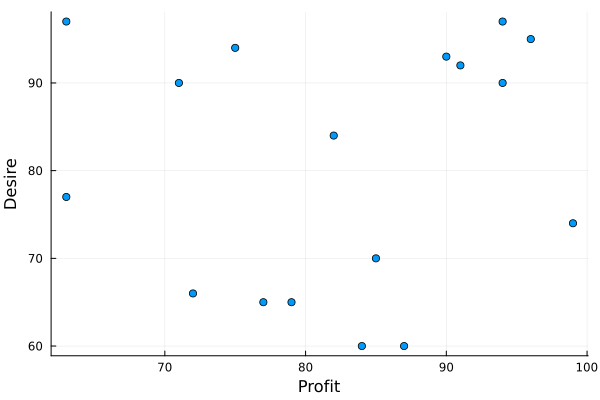

In [4]:
Plots.scatter(
    profit,
    desire;
    xlabel = "Profit",
    ylabel = "Desire",
    legend = false,
)

The goal of the bi-objective knapsack problem is to choose a subset which
maximizes both objectives.

## JuMP formulation

Our JuMP formulation is a direct translation of the mathematical formulation:

In [6]:
model = Model()
@variable(model, x[1:N], Bin)
@constraint(model, sum(weight[i] * x[i] for i in 1:N) <= capacity)
@expression(model, profit_expr, sum(profit[i] * x[i] for i in 1:N))
@expression(model, desire_expr, sum(desire[i] * x[i] for i in 1:N))
@objective(model, Max, [profit_expr, desire_expr])

2-element Vector{AffExpr}:
 77 x[1] + 94 x[2] + 71 x[3] + 63 x[4] + 96 x[5] + 82 x[6] + 85 x[7] + 75 x[8] + 72 x[9] + 91 x[10] + 99 x[11] + 63 x[12] + 84 x[13] + 87 x[14] + 79 x[15] + 94 x[16] + 90 x[17]
 65 x[1] + 90 x[2] + 90 x[3] + 77 x[4] + 95 x[5] + 84 x[6] + 70 x[7] + 94 x[8] + 66 x[9] + 92 x[10] + 74 x[11] + 97 x[12] + 60 x[13] + 60 x[14] + 65 x[15] + 97 x[16] + 93 x[17]

Note how we form a multi-objective program by passing a vector of scalar
objective functions.

## Solution

To solve our model, we need an optimizer which supports multi-objective linear
programs. One option is to use the MultiObjectiveAlgorithms.jl
package.

In [7]:
set_optimizer(model, () -> MOA.Optimizer(HiGHS.Optimizer))

MultiObjectiveAlgorithms.jl supports many different algorithms for solving
multiobjective optimization problems. One option is the epsilon-constraint
method:

In [8]:
set_attribute(model, MOA.Algorithm(), MOA.EpsilonConstraint())

Let's solve the problem and see the solution

In [9]:
optimize!(model)

----------------------------------------------
        MultiObjectiveAlgorithms.jl
----------------------------------------------
Algorithm: EpsilonConstraint
----------------------------------------------
solve #     Obj. 1       Obj. 2       Time    
----------------------------------------------
    1   -9.55000e+02 -9.06000e+02  3.13452e+00
    2   -9.55000e+02 -9.06000e+02  3.13929e+00
    3   -9.18000e+02 -9.83000e+02  3.15492e+00
    4   -9.18000e+02 -9.83000e+02  3.16529e+00
    6   -9.27000e+02 -9.72000e+02  3.20578e+00
    8   -9.34000e+02 -9.71000e+02  3.22145e+00
   10   -9.35000e+02 -9.47000e+02  3.26393e+00
   12   -9.36000e+02 -9.42000e+02  3.33315e+00
   14   -9.43000e+02 -9.40000e+02  3.36220e+00
   16   -9.48000e+02 -9.39000e+02  3.38424e+00
   18   -9.49000e+02 -9.15000e+02  3.40903e+00
   20   -9.55000e+02 -9.06000e+02  3.41634e+00
----------------------------------------------
termination_status: OPTIMAL
result_count: 9

Total solve time:          3.46247e+00
Time 

In [10]:
assert_is_solved_and_feasible(model)
solution_summary(model)

solution_summary(; result = 1, verbose = false)
├ solver_name          : MOA[algorithm=MultiObjectiveAlgorithms.EpsilonConstraint, optimizer=HiGHS]
├ Termination
│ ├ termination_status : OPTIMAL
│ ├ result_count       : 9
│ ├ raw_status         : Solve complete. Found 9 solution(s)
│ └ objective_bound    : [9.55000e+02,9.83000e+02]
├ Solution (result = 1)
│ ├ primal_status        : FEASIBLE_POINT
│ ├ dual_status          : NO_SOLUTION
│ └ objective_value      : [9.55000e+02,9.06000e+02]
└ Work counters
  └ solve_time (sec)   : 3.46247e+00

There are 9 solutions available. We can also use `result_count` to see
how many solutions are available:

In [11]:
result_count(model)

9

## Accessing multiple solutions

Access the nine different solutions in the model using the `result` keyword to
`solution_summary`, `value`, and `objective_value`:

In [12]:
solution_summary(model; result = 5)

solution_summary(; result = 5, verbose = false)
└ Solution (result = 5)
  ├ primal_status        : FEASIBLE_POINT
  ├ dual_status          : NO_SOLUTION
  └ objective_value      : [9.36000e+02,9.42000e+02]

In [13]:
@assert primal_status(model; result = 5) == FEASIBLE_POINT

In [14]:
assert_is_solved_and_feasible(model; result = 5)

In [15]:
objective_value(model; result = 5)

2-element Vector{Float64}:
 936.0
 942.0

Note that because we set a vector of two objective functions, the objective
value is a vector with two elements. We can also query the value of each
objective separately:

In [16]:
value(profit_expr; result = 5)

936.0

## Visualizing objective space

Unlike single-objective optimization problems, multi-objective optimization
problems do not have a single optimal solution. Instead, the solutions
returned represent possible trade-offs that the decision maker can choose
between the two objectives. A common way to visualize this is by plotting
the objective values of each of the solutions:

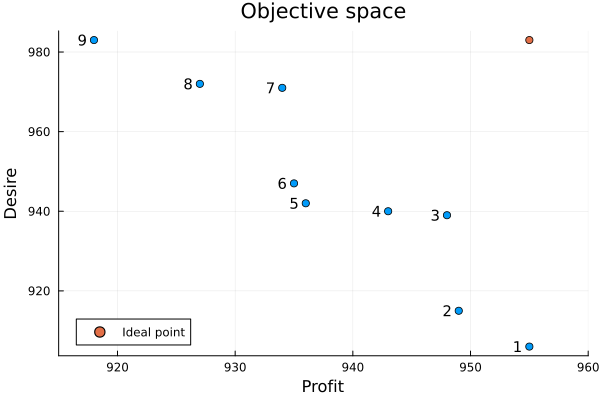

In [17]:
plot = Plots.scatter(
    [value(profit_expr; result = i) for i in 1:result_count(model)],
    [value(desire_expr; result = i) for i in 1:result_count(model)];
    xlabel = "Profit",
    ylabel = "Desire",
    title = "Objective space",
    label = "",
    xlims = (915, 960),
)
for i in 1:result_count(model)
    y = objective_value(model; result = i)
    Plots.annotate!(y[1] - 1, y[2], (i, 10))
end
ideal_point = objective_bound(model)
Plots.scatter!([ideal_point[1]], [ideal_point[2]]; label = "Ideal point")

Visualizing the objective space lets the decision maker choose a solution that
suits their personal preferences. For example, result `#7` is close to the
maximum value of desire, but offers significantly higher profit compared
with solutions `#8` and `#9`.

The set of items that are chosen in solution `#7` are:

In [18]:
items_chosen = [i for i in 1:N if value(x[i]; result = 7) > 0.9]

11-element Vector{Int64}:
  2
  3
  5
  6
  8
 10
 11
 12
 15
 16
 17

## Next steps

MultiObjectiveAlgorithms.jl implements a number of different
algorithms. Try solving the same problem using `MOA.Dichotomy()`. Does it find
the same solution?

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*